In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 中文字体配置：系统字体为 .ttc 集合，Matplotlib 仅识别其中的 Noto Sans CJK JP 变体
# 该字体覆盖全部 CJK 汉字，可正常显示简体中文，不会出现 Glyph missing 警告
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK JP', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

<Axes: >

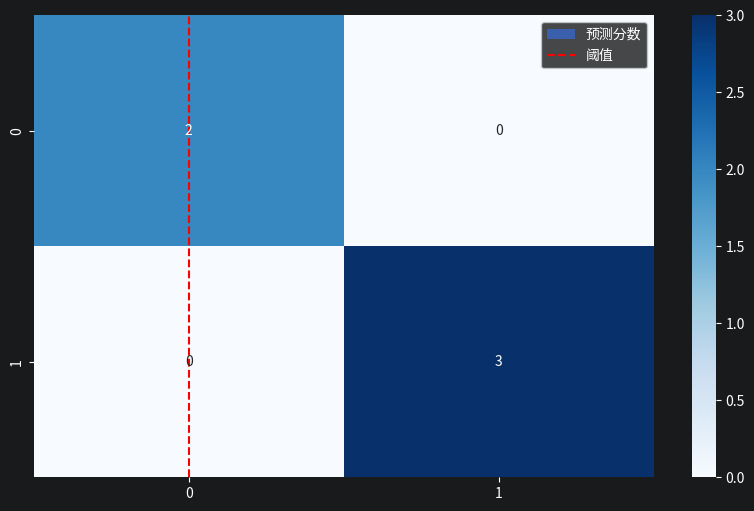

In [10]:
#预测概率
predictions = np.array([0.9,0.3,0.8,0.2,0.7])
#标识
labels = np.array([1,0,1,0,1])


# 将连续概率预测转为二分类标签：预测值 > 0.5 判定为正类(1)，否则为负类(0)
# .astype(int) 将布尔值(True/False)转换为整数(1/0)，方便与真实标签比较
# 二分类标签
binary_pred = (predictions > 0.5).astype(int)

# 逐元素比较预测标签与真实标签是否一致，得到布尔数组
# np.mean 计算 True 所占比例，即为预测正确的样本比例（准确率）
accuracy = np.mean(binary_pred == labels)

# ===== 预测分数分布直方图 =====


plt.figure(figsize=(10, 6))          # 创建画布，尺寸为 10x6 英寸
plt.hist(predictions,                # 绘制预测分数的直方图
         bins=50,                    # 划分为 50 个区间（桶）
         alpha=0.7,                  # 透明度 0.7，便于观察重叠部分
         label='预测分数')            # 图例标签
plt.axvline(x=0.5,                   # 在 x=0.5 处画一条竖线（分类阈值）
            color='r',               # ⚠️ 原代码 clor 拼写错误，应为 color
            linestyle='--',          # 虚线样式
            label='阈值')            # 图例标签
plt.xlabel('预测分数')               # x 轴名称
plt.ylabel('频次')                   # y 轴名称
plt.legend()                         # 显示图例
plt.savefig('prediction_distribution.png')  # 保存图片到当前目录


#混淆矩阵热力图
from sklearn.metrics import confusion_matrix
# 构建混淆矩阵：y_true 为真实标签，y_pred 为二分类预测标签
# ⚠️ 注意：此处 y_pred 应传二分类结果 binary_pred（0/1），而不是连续概率 predictions，否则 sklearn 会报错
cm = confusion_matrix(y_true=labels, y_pred=binary_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

